# 04 — Demonstração de detecções e mensagens em texto

Este notebook é uma demonstração qualitativa do detector e das regras históricas.
As imagens de exemplo são escolhidas automaticamente. Os CSVs são saídas prontas.
Não há preenchimento manual nem geração de áudio.

As regras foram extraídas da V2 original e centralizadas em `src/politica_alertas.py`.
Para avaliação de todas as imagens, com detecções extras e objetos não detectados,
use o notebook 05d. Os exemplos deste notebook não medem acurácia de risco físico.


## 1. Pré-requisitos

O modelo treinado deve estar em:

```text
tcc_visao_computacional/
└── models/
    └── yolov8n_baseline/
        └── best.pt
```

E o dataset processado em:

```text
data/processed/homeobjects_yolo/
```

## 2. Importações e localização do projeto

In [1]:
from pathlib import Path
from datetime import datetime
import random
import sys

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, ImageDraw


def localizar_raiz_projeto() -> Path:
    atual = Path.cwd().resolve()

    for candidata in [atual, *atual.parents]:
        if (
            (candidata / "src/politica_alertas.py").is_file()
        ):
            return candidata

    raise FileNotFoundError(
        "Não foi possível localizar a raiz do projeto."
    )


RAIZ_PROJETO = localizar_raiz_projeto()

if str(RAIZ_PROJETO) not in sys.path:
    sys.path.insert(0, str(RAIZ_PROJETO))

print("Raiz do projeto:", RAIZ_PROJETO)


Raiz do projeto: C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional


## 3. Importar Ultralytics

In [2]:
try:
    from ultralytics import YOLO
except ImportError:
    import subprocess

    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "ultralytics"]
    )

    from ultralytics import YOLO

print("Ultralytics importado com sucesso.")

Ultralytics importado com sucesso.


## 4. Caminhos do projeto

In [3]:
CAMINHO_MODELO = RAIZ_PROJETO / "models/yolov8n_retreino_01/best.pt"
PASTA_TEST = RAIZ_PROJETO / "data/processed/homeobjects_yolo/images/test"
IDENTIFICADOR = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
PASTA_EXECUCAO = RAIZ_PROJETO / 'reports/demonstracao_risco' / 'v2' / IDENTIFICADOR
PASTA_RESULTADOS = PASTA_EXECUCAO / 'imagens'
PASTA_TABELAS = PASTA_EXECUCAO / 'tabelas'
if not CAMINHO_MODELO.is_file():
    raise FileNotFoundError(f'Modelo não encontrado: {CAMINHO_MODELO}')
if not PASTA_TEST.is_dir():
    raise FileNotFoundError(f'TEST não encontrado: {PASTA_TEST}')
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=False)
PASTA_TABELAS.mkdir(parents=True, exist_ok=False)
print('Modelo:', CAMINHO_MODELO)
print('Resultados desta demonstração:', PASTA_EXECUCAO)


Modelo: C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\models\yolov8n_retreino_01\best.pt
Resultados desta demonstração: C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\reports\demonstracao_risco\v2\20261013_020804_917414


# 5. Relevância das classes

As 12 classes continuam sendo detectadas pelo YOLO.

Para avaliação de locomoção:

### Possíveis obstáculos físicos
- bed
- sofa
- chair
- table
- wardrobe
- potted plant

### Contextuais
- lamp
- door

### Ignoradas para risco
- tv
- laptop
- window
- photo frame

In [4]:
from src.politica_alertas import (
    PESO_OBJETO, CLASSES_CONTEXTUAIS, CLASSES_IGNORADAS,
    LIMITE_ESQUERDA, LIMITE_DIREITA, LIMITE_AREA_MEDIA, LIMITE_AREA_GRANDE,
    LIMITE_VERTICAL_SUPERIOR, LIMITE_VERTICAL_INFERIOR,
    PESO_POSICAO, PESO_TAMANHO, AJUSTE_VERTICAL,
    classificar_posicao, classificar_tamanho, classificar_posicao_vertical,
    classificar_risco_v1, classificar_risco_v2, gerar_mensagens_tabela,
)


## Regras espaciais fixas

O centro horizontal da caixa define a posição em três terços da largura:

| Região | Centro horizontal normalizado |
|---|---|
| Esquerda | menor que 1/3 |
| Centro | de 1/3 até menos de 2/3 |
| Direita | 2/3 ou mais |

A área da caixa dividida pela área da imagem define o tamanho:
pequeno abaixo de 5%, médio de 5% até menos de 20%, grande a partir de 20%.
Na V2, a base inferior da caixa define a região vertical: superior abaixo de 60%,
intermediária de 60% até menos de 80%, inferior a partir de 80% da altura.
A V1 ignora esse ajuste vertical. Os parâmetros reproduzem a política histórica
e não são ajustados a partir dos resultados do TEST.


In [5]:
# Limiares importados da política original; não reestimados com o TEST.


## 7. Funções de classificação

In [6]:
# Funções importadas de src.politica_alertas.


## 8. Regra V1

A regra original utiliza:

```text
tipo do objeto
+ posição horizontal
+ tamanho
```

In [7]:
# Funções importadas de src.politica_alertas.


## 9. Regra V2

A V2 parte da pontuação da V1 e aplica:

```text
região superior       → -2 pontos
região intermediária  → -1 ponto
região inferior       →  0 pontos
```

In [8]:
# Funções importadas de src.politica_alertas.


## 10. Carregar o modelo

In [9]:
modelo = YOLO(str(CAMINHO_MODELO))

print("Modelo carregado.")
print("Classes:")
print(modelo.names)

Modelo carregado.
Classes:
{0: 'bed', 1: 'sofa', 2: 'chair', 3: 'table', 4: 'lamp', 5: 'tv', 6: 'laptop', 7: 'wardrobe', 8: 'window', 9: 'door', 10: 'potted plant', 11: 'photo frame'}


# 11. Análise completa de uma imagem

A função abaixo retorna, para cada detecção:

- classe;
- confiança;
- bounding box;
- posição horizontal;
- tamanho;
- posição vertical;
- risco V1;
- risco V2.

In [10]:
def analisar_imagem(
    caminho_imagem,
    confianca_minima=0.25,
):
    caminho_imagem = Path(caminho_imagem)

    imagem = Image.open(caminho_imagem).convert("RGB")
    largura, altura = imagem.size
    area_imagem = largura * altura

    resultados = modelo.predict(
        source=str(caminho_imagem),
        conf=confianca_minima,
        verbose=False,
    )

    resultado = resultados[0]
    registros = []

    if resultado.boxes is None:
        return pd.DataFrame(), imagem

    for box in resultado.boxes:
        classe_id = int(box.cls[0].item())
        classe = modelo.names[classe_id]
        confianca = float(box.conf[0].item())

        x1, y1, x2, y2 = [
            float(valor)
            for valor in box.xyxy[0].tolist()
        ]

        largura_box = x2 - x1
        altura_box = y2 - y1
        area_box = largura_box * altura_box

        centro_x = (x1 + x2) / 2

        posicao = classificar_posicao(
            centro_x=centro_x,
            largura_imagem=largura,
        )

        tamanho, proporcao_area = classificar_tamanho(
            area_box=area_box,
            area_imagem=area_imagem,
        )

        posicao_vertical, proporcao_vertical = (
            classificar_posicao_vertical(
                y2=y2,
                altura_imagem=altura,
            )
        )

        avaliacao_v1 = classificar_risco_v1(
            classe=classe,
            posicao=posicao,
            tamanho=tamanho,
        )

        avaliacao_v2 = classificar_risco_v2(
            classe=classe,
            posicao=posicao,
            tamanho=tamanho,
            posicao_vertical=posicao_vertical,
        )

        registros.append(
            {
                "arquivo": caminho_imagem.name,
                "classe": classe,
                "confianca": confianca,
                "x1": x1,
                "y1": y1,
                "x2": x2,
                "y2": y2,
                "posicao": posicao,
                "ocupacao_imagem": proporcao_area,
                "tamanho": tamanho,
                "posicao_vertical": posicao_vertical,
                "proporcao_vertical": proporcao_vertical,
                "pontuacao_v1": avaliacao_v1["pontuacao"],
                "nivel_risco_v1": avaliacao_v1["nivel_risco"],
                "ajuste_vertical": avaliacao_v2["ajuste_vertical"],
                "pontuacao_v2": avaliacao_v2["pontuacao"],
                "nivel_risco_v2": avaliacao_v2["nivel_risco"],
                "motivo": avaliacao_v2["motivo"],
            }
        )

    return pd.DataFrame(registros), imagem

## 12. Selecionar uma imagem do TEST

In [11]:
EXTENSOES_IMAGEM = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

imagens_test = sorted(
    arquivo
    for arquivo in PASTA_TEST.rglob("*")
    if arquivo.is_file()
    and arquivo.suffix.lower() in EXTENSOES_IMAGEM
)

if not imagens_test:
    raise RuntimeError("Nenhuma imagem encontrada no conjunto TEST.")

random.seed(42)
imagem_teste = random.choice(imagens_test)

print("Imagem selecionada:")
print(imagem_teste)

Imagem selecionada:
C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\data\processed\homeobjects_yolo\images\test\living_room_712.jpg


## 13. Executar a avaliação

In [12]:
df_deteccoes, imagem_original = analisar_imagem(
    imagem_teste,
    confianca_minima=0.25,
)

colunas_exibicao = [
    "classe",
    "confianca",
    "posicao",
    "ocupacao_imagem",
    "tamanho",
    "posicao_vertical",
    "proporcao_vertical",
    "pontuacao_v1",
    "nivel_risco_v1",
    "ajuste_vertical",
    "pontuacao_v2",
    "nivel_risco_v2",
]

if df_deteccoes.empty:
    print("Nenhum objeto detectado.")
else:
    display(
        df_deteccoes[colunas_exibicao]
        .sort_values(
            ["nivel_risco_v2", "confianca"],
            ascending=[True, False],
        )
    )

,classe,confianca,posicao,ocupacao_imagem,tamanho,posicao_vertical,proporcao_vertical,pontuacao_v1,nivel_risco_v1,ajuste_vertical,pontuacao_v2,nivel_risco_v2
2,table,0.725217,centro,0.374915,grande,inferior,1.000000,9.0,alto,0,9.0,alto
8,wardrobe,0.252361,centro,0.390398,grande,inferior,1.000000,9.0,alto,0,9.0,alto
4,potted plant,0.599235,direita,0.004090,pequeno,superior,0.395852,4.0,baixo,-2,2.0,baixo
3,door,0.647616,esquerda,0.062751,medio,superior,0.585071,NaN,contextual,0,NaN,contextual
7,door,0.284415,esquerda,0.030490,pequeno,superior,0.586691,NaN,contextual,0,NaN,contextual
6,photo frame,0.289952,centro,0.008201,pequeno,superior,0.405427,0.0,ignorado,0,0.0,ignorado
0,wardrobe,0.840585,direita,0.086570,medio,intermediaria,0.715445,6.0,medio,-1,5.0,medio
1,potted plant,0.838002,centro,0.082502,medio,intermediaria,0.659847,7.0,alto,-1,6.0,medio
5,chair,0.294970,esquerda,0.124463,medio,inferior,1.000000,6.0,medio,0,6.0,medio


# 14. Visualização

A imagem é dividida em:

- três regiões horizontais;
- três regiões verticais.

O texto de cada bounding box mostra a classificação **V2**.

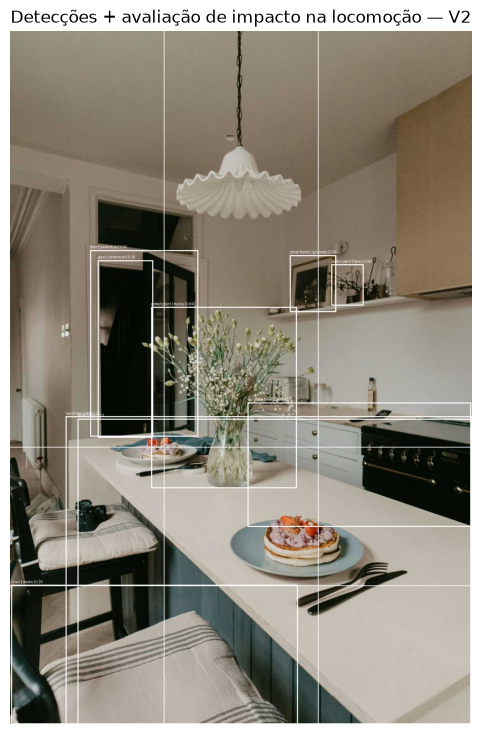

In [13]:
def desenhar_resultados(
    imagem,
    df,
):
    imagem_saida = imagem.copy()
    desenho = ImageDraw.Draw(imagem_saida)

    largura, altura = imagem_saida.size

    x_esquerda = int(largura * LIMITE_ESQUERDA)
    x_direita = int(largura * LIMITE_DIREITA)

    y_superior = int(
        altura * LIMITE_VERTICAL_SUPERIOR
    )

    y_inferior = int(
        altura * LIMITE_VERTICAL_INFERIOR
    )

    desenho.line(
        [(x_esquerda, 0), (x_esquerda, altura)],
        width=2,
    )

    desenho.line(
        [(x_direita, 0), (x_direita, altura)],
        width=2,
    )

    desenho.line(
        [(0, y_superior), (largura, y_superior)],
        width=2,
    )

    desenho.line(
        [(0, y_inferior), (largura, y_inferior)],
        width=2,
    )

    for _, linha in df.iterrows():
        caixa = (
            linha["x1"],
            linha["y1"],
            linha["x2"],
            linha["y2"],
        )

        desenho.rectangle(
            caixa,
            width=3,
        )

        texto = (
            f'{linha["classe"]} | '
            f'{linha["nivel_risco_v2"]} | '
            f'{linha["confianca"]:.2f}'
        )

        desenho.text(
            (linha["x1"], max(linha["y1"] - 15, 0)),
            texto,
        )

    return imagem_saida


imagem_anotada = desenhar_resultados(
    imagem_original,
    df_deteccoes,
)

plt.figure(figsize=(14, 9))
plt.imshow(imagem_anotada)
plt.axis("off")
plt.title("Detecções + avaliação de impacto na locomoção — V2")
plt.show()

## 15. Comparar V1 e V2 na imagem selecionada

In [14]:
if not df_deteccoes.empty:
    comparacao_imagem = df_deteccoes[
        [
            "classe",
            "posicao",
            "tamanho",
            "posicao_vertical",
            "pontuacao_v1",
            "nivel_risco_v1",
            "ajuste_vertical",
            "pontuacao_v2",
            "nivel_risco_v2",
        ]
    ].copy()

    comparacao_imagem["mudou"] = (
        comparacao_imagem["nivel_risco_v1"]
        != comparacao_imagem["nivel_risco_v2"]
    )

    display(comparacao_imagem)

,classe,posicao,tamanho,posicao_vertical,pontuacao_v1,nivel_risco_v1,ajuste_vertical,pontuacao_v2,nivel_risco_v2,mudou
0,wardrobe,direita,medio,intermediaria,6.0,medio,-1,5.0,medio,False
1,potted plant,centro,medio,intermediaria,7.0,alto,-1,6.0,medio,True
2,table,centro,grande,inferior,9.0,alto,0,9.0,alto,False
3,door,esquerda,medio,superior,NaN,contextual,0,NaN,contextual,False
4,potted plant,direita,pequeno,superior,4.0,baixo,-2,2.0,baixo,False
5,chair,esquerda,medio,inferior,6.0,medio,0,6.0,medio,False
6,photo frame,centro,pequeno,superior,0.0,ignorado,0,0.0,ignorado,False
7,door,esquerda,pequeno,superior,NaN,contextual,0,NaN,contextual,False
8,wardrobe,centro,grande,inferior,9.0,alto,0,9.0,alto,False


## 16. Mensagens usando a regra V2

In [15]:
def gerar_mensagens(df):
    return gerar_mensagens_tabela(df, coluna='nivel_risco_v2')
mensagens = gerar_mensagens(df_deteccoes)
for mensagem in mensagens:
    print(mensagem)


Atenção: guarda-roupa detectado na região central da imagem. Prioridade alta.
Atenção: mesa detectada na região central da imagem. Prioridade alta.
Atenção: cadeira detectada na região esquerda da imagem. Prioridade média.
Atenção: guarda-roupa detectado na região direita da imagem. Prioridade média.
Atenção: planta em vaso detectada na região central da imagem. Prioridade média.


# 17. Testar 20 imagens do TEST

Agora aplicamos a regra V1 e a V2 sobre a mesma amostra de 20 imagens.

In [16]:
random.seed(42)

quantidade_amostras = min(20, len(imagens_test))

amostras = random.sample(
    imagens_test,
    quantidade_amostras,
)

resultados_amostras = []

for indice, caminho_imagem in enumerate(amostras, start=1):
    print(
        f"[{indice:02d}/{quantidade_amostras}] "
        f"{caminho_imagem.name}"
    )

    df_imagem, _ = analisar_imagem(
        caminho_imagem,
        confianca_minima=0.25,
    )

    if not df_imagem.empty:
        resultados_amostras.append(df_imagem)

if resultados_amostras:
    df_amostras = pd.concat(
        resultados_amostras,
        ignore_index=True,
    )
else:
    df_amostras = pd.DataFrame()

print()
print("Detecções analisadas:", len(df_amostras))

[01/20] living_room_712.jpg
[02/20] living_room_1p (118).jpg
[03/20] living_room_1040.jpg
[04/20] living_room_908.jpg
[05/20] living_room_1p (439).jpg
[06/20] living_room_1p (382).jpg
[07/20] living_room_1p (339).jpg
[08/20] living_room_1p (173).jpg
[09/20] living_room_900.jpg
[10/20] living_room_1p (10).jpg
[11/20] living_room_780.jpg
[12/20] living_room_538.jpg
[13/20] living_room_168.jpg
[14/20] living_room_62.jpg
[15/20] living_room_303.jpg
[16/20] living_room_1059.jpg
[17/20] living_room_1055.jpg
[18/20] living_room_180.jpg
[19/20] living_room_1p (326).jpg
[20/20] living_room_1p (357).jpg

Detecções analisadas: 208


## 18. Resumo V1

In [17]:
if not df_amostras.empty:
    resumo_v1 = (
        df_amostras
        .groupby(
            ["nivel_risco_v1", "classe"],
            dropna=False,
        )
        .size()
        .reset_index(name="quantidade")
        .sort_values(
            ["nivel_risco_v1", "quantidade"],
            ascending=[True, False],
        )
    )

    display(resumo_v1)

,nivel_risco_v1,classe,quantidade
3,alto,sofa,11
4,alto,table,10
2,alto,potted plant,5
1,alto,chair,3
5,alto,wardrobe,3
0,alto,bed,2
6,baixo,potted plant,31
8,contextual,lamp,16
7,contextual,door,6
9,ignorado,photo frame,29


## 19. Resumo V2

In [18]:
if not df_amostras.empty:
    resumo_v2 = (
        df_amostras
        .groupby(
            ["nivel_risco_v2", "classe"],
            dropna=False,
        )
        .size()
        .reset_index(name="quantidade")
        .sort_values(
            ["nivel_risco_v2", "quantidade"],
            ascending=[True, False],
        )
    )

    display(resumo_v2)

,nivel_risco_v2,classe,quantidade
2,alto,sofa,11
3,alto,table,8
0,alto,bed,2
4,alto,wardrobe,2
1,alto,chair,1
6,baixo,potted plant,40
7,baixo,table,4
5,baixo,chair,3
8,baixo,wardrobe,2
10,contextual,lamp,16


# 20. Comparação global V1 x V2

Esta tabela mostra quantas detecções mudaram de classificação.

In [19]:
if not df_amostras.empty:
    comparacao = pd.crosstab(
        df_amostras["nivel_risco_v1"],
        df_amostras["nivel_risco_v2"],
        margins=True,
    )

    display(comparacao)

    alteracoes = (
        df_amostras["nivel_risco_v1"]
        != df_amostras["nivel_risco_v2"]
    ).sum()

    total = len(df_amostras)

    print(
        f"Detecções que mudaram de classificação: "
        f"{alteracoes} de {total} "
        f"({alteracoes / total:.2%})"
    )

nivel_risco_v2,alto,baixo,contextual,ignorado,medio,All
nivel_risco_v1,,,,,,
alto,24,0,0,0,10,34
baixo,0,31,0,0,0,31
contextual,0,0,22,0,0,22
ignorado,0,0,0,57,0,57
medio,0,18,0,0,46,64
All,24,49,22,57,56,208


Detecções que mudaram de classificação: 28 de 208 (13.46%)


## 21. Quantidade de alertas produzidos

Esta contagem compara o comportamento das regras na amostra. Uma redução da quantidade não comprova redução de falsos alertas ou de risco físico.


In [20]:
if not df_amostras.empty:
    alertas_v1 = df_amostras[
        df_amostras["nivel_risco_v1"].isin(["medio", "alto"])
    ].shape[0]

    alertas_v2 = df_amostras[
        df_amostras["nivel_risco_v2"].isin(["medio", "alto"])
    ].shape[0]

    riscos_altos_v1 = (
        df_amostras["nivel_risco_v1"] == "alto"
    ).sum()

    riscos_altos_v2 = (
        df_amostras["nivel_risco_v2"] == "alto"
    ).sum()

    df_alertas = pd.DataFrame(
        [
            {
                "versao": "V1",
                "alertas_medio_alto": alertas_v1,
                "riscos_altos": riscos_altos_v1,
            },
            {
                "versao": "V2",
                "alertas_medio_alto": alertas_v2,
                "riscos_altos": riscos_altos_v2,
            },
        ]
    )

    display(df_alertas)

,versao,alertas_medio_alto,riscos_altos
0,V1,98,34
1,V2,80,24


## 22. Diagnóstico automático de mudanças

A tabela é informativa e não exige classificação manual. Não ajuste a regra a partir do TEST.


In [21]:
if not df_amostras.empty:
    df_mudancas = df_amostras[
        df_amostras["nivel_risco_v1"]
        != df_amostras["nivel_risco_v2"]
    ].copy()

    colunas_mudancas = [
        "arquivo",
        "classe",
        "confianca",
        "posicao",
        "tamanho",
        "posicao_vertical",
        "proporcao_vertical",
        "pontuacao_v1",
        "nivel_risco_v1",
        "ajuste_vertical",
        "pontuacao_v2",
        "nivel_risco_v2",
    ]

    display(
        df_mudancas[colunas_mudancas]
        .sort_values(
            ["arquivo", "classe"]
        )
    )

    print("Total de mudanças:", len(df_mudancas))

,arquivo,classe,confianca,posicao,tamanho,posicao_vertical,proporcao_vertical,pontuacao_v1,nivel_risco_v1,ajuste_vertical,pontuacao_v2,nivel_risco_v2
31,living_room_1040.jpg,table,0.573445,direita,pequeno,intermediaria,0.680115,5.0,medio,-1,4.0,baixo
161,living_room_1055.jpg,table,0.636602,centro,pequeno,intermediaria,0.753315,7.0,alto,-1,6.0,medio
146,living_room_1059.jpg,potted plant,0.719880,centro,medio,intermediaria,0.614441,7.0,alto,-1,6.0,medio
138,living_room_1059.jpg,table,0.912520,centro,pequeno,intermediaria,0.786299,7.0,alto,-1,6.0,medio
139,living_room_1059.jpg,table,0.906397,esquerda,pequeno,intermediaria,0.779300,5.0,medio,-1,4.0,baixo
170,living_room_180.jpg,chair,0.843233,esquerda,pequeno,intermediaria,0.729208,5.0,medio,-1,4.0,baixo
172,living_room_180.jpg,potted plant,0.794787,centro,medio,intermediaria,0.650160,7.0,alto,-1,6.0,medio
97,living_room_1p (10).jpg,potted plant,0.831534,centro,pequeno,superior,0.284380,6.0,medio,-2,4.0,baixo
102,living_room_1p (10).jpg,potted plant,0.381336,centro,pequeno,superior,0.285485,6.0,medio,-2,4.0,baixo
13,living_room_1p (118).jpg,potted plant,0.677584,centro,pequeno,superior,0.510613,6.0,medio,-2,4.0,baixo


Total de mudanças: 28


## 23. Salvar resultados

In [22]:
if not df_amostras.empty:
    caminho_csv = (
        PASTA_TABELAS
        / "avaliacao_risco_v1_v2_amostras.csv"
    )

    df_amostras.to_csv(
        caminho_csv,
        index=False,
        encoding="utf-8-sig",
    )

    print("Tabela completa salva em:")
    print(caminho_csv)

    if "df_mudancas" in globals():
        caminho_mudancas = (
            PASTA_TABELAS
            / "avaliacao_risco_mudancas_v1_v2.csv"
        )

        df_mudancas.to_csv(
            caminho_mudancas,
            index=False,
            encoding="utf-8-sig",
        )

        print()
        print("Mudanças V1 x V2 salvas em:")
        print(caminho_mudancas)

caminho_imagem_saida = (
    PASTA_RESULTADOS
    / "exemplo_avaliacao_risco_v2.jpg"
)

imagem_anotada.save(caminho_imagem_saida)

print()
print("Imagem salva em:")
print(caminho_imagem_saida)

Tabela completa salva em:
C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\reports\demonstracao_risco\v2\20261013_020804_917414\tabelas\avaliacao_risco_v1_v2_amostras.csv

Mudanças V1 x V2 salvas em:
C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\reports\demonstracao_risco\v2\20261013_020804_917414\tabelas\avaliacao_risco_mudancas_v1_v2.csv

Imagem salva em:
C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\reports\demonstracao_risco\v2\20261013_020804_917414\imagens\exemplo_avaliacao_risco_v2.jpg


## 24. Interpretação

A quantidade de alertas não comprova sua correção física. Esta comparação descreve
o comportamento das regras históricas. A avaliação quantitativa atual é feita no 05d
contra as anotações da base e contra a referência da política fixa.

A conferência visual de algumas amostras é opcional. Não é preciso preencher
gabarito por imagem ou criar novos cenários manuais. A saída final é uma mensagem
em texto, quando prioridade média ou alta acionar a política.
